# Dataset Description
## Colombia's share of South America GDP

**Source**: [IMF](https://data.imf.org/en/Data-Explorer?datasetUrn=IMF.RES:WEO(9.0.0))

# Code
## Imports

In [1]:
import textwrap
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.ops import polylabel
from shapely.geometry import Point, box

## Load data

In [2]:
path = "./data/gdp_south_america.csv"

df = pd.read_csv(path, encoding="utf-8")

## Clean data

In [3]:
df.drop(columns=["INDICATOR", "FREQUENCY", "SCALE"], inplace=True)

result = df.set_index("COUNTRY").T
result.index = result.index.astype(int)
result.index.name = "year"
result.columns.name = None

result["total"] = result.sum(axis=1)

shares = result.drop(columns="total").div(result["total"], axis=0) * 100

shares = shares[shares.index <= 2025]

## Load map

In [4]:
map_path = "./data/ne_50m_countries/ne_50m_admin_0_countries.shp"
BBOX = (-82, -56, -34, 13.5)  # lon_min, lat_min, lon_max, lat_max
CRS = "ESRI:102033"  # South America Albers Equal Area Conic

world = gpd.read_file(map_path, bbox=BBOX)
world = world[world["CONTINENT"].isin(["South America"]) | (world["ADMIN"] == "France")]
world = world.clip(BBOX)[["ADMIN", "geometry"]]

share_2025 = shares.loc[2025].rename(
    {"Venezuela, República Bolivariana de": "Venezuela"}
)
world["share"] = world["ADMIN"].map(share_2025)
world = world.to_crs(CRS)

## Plot

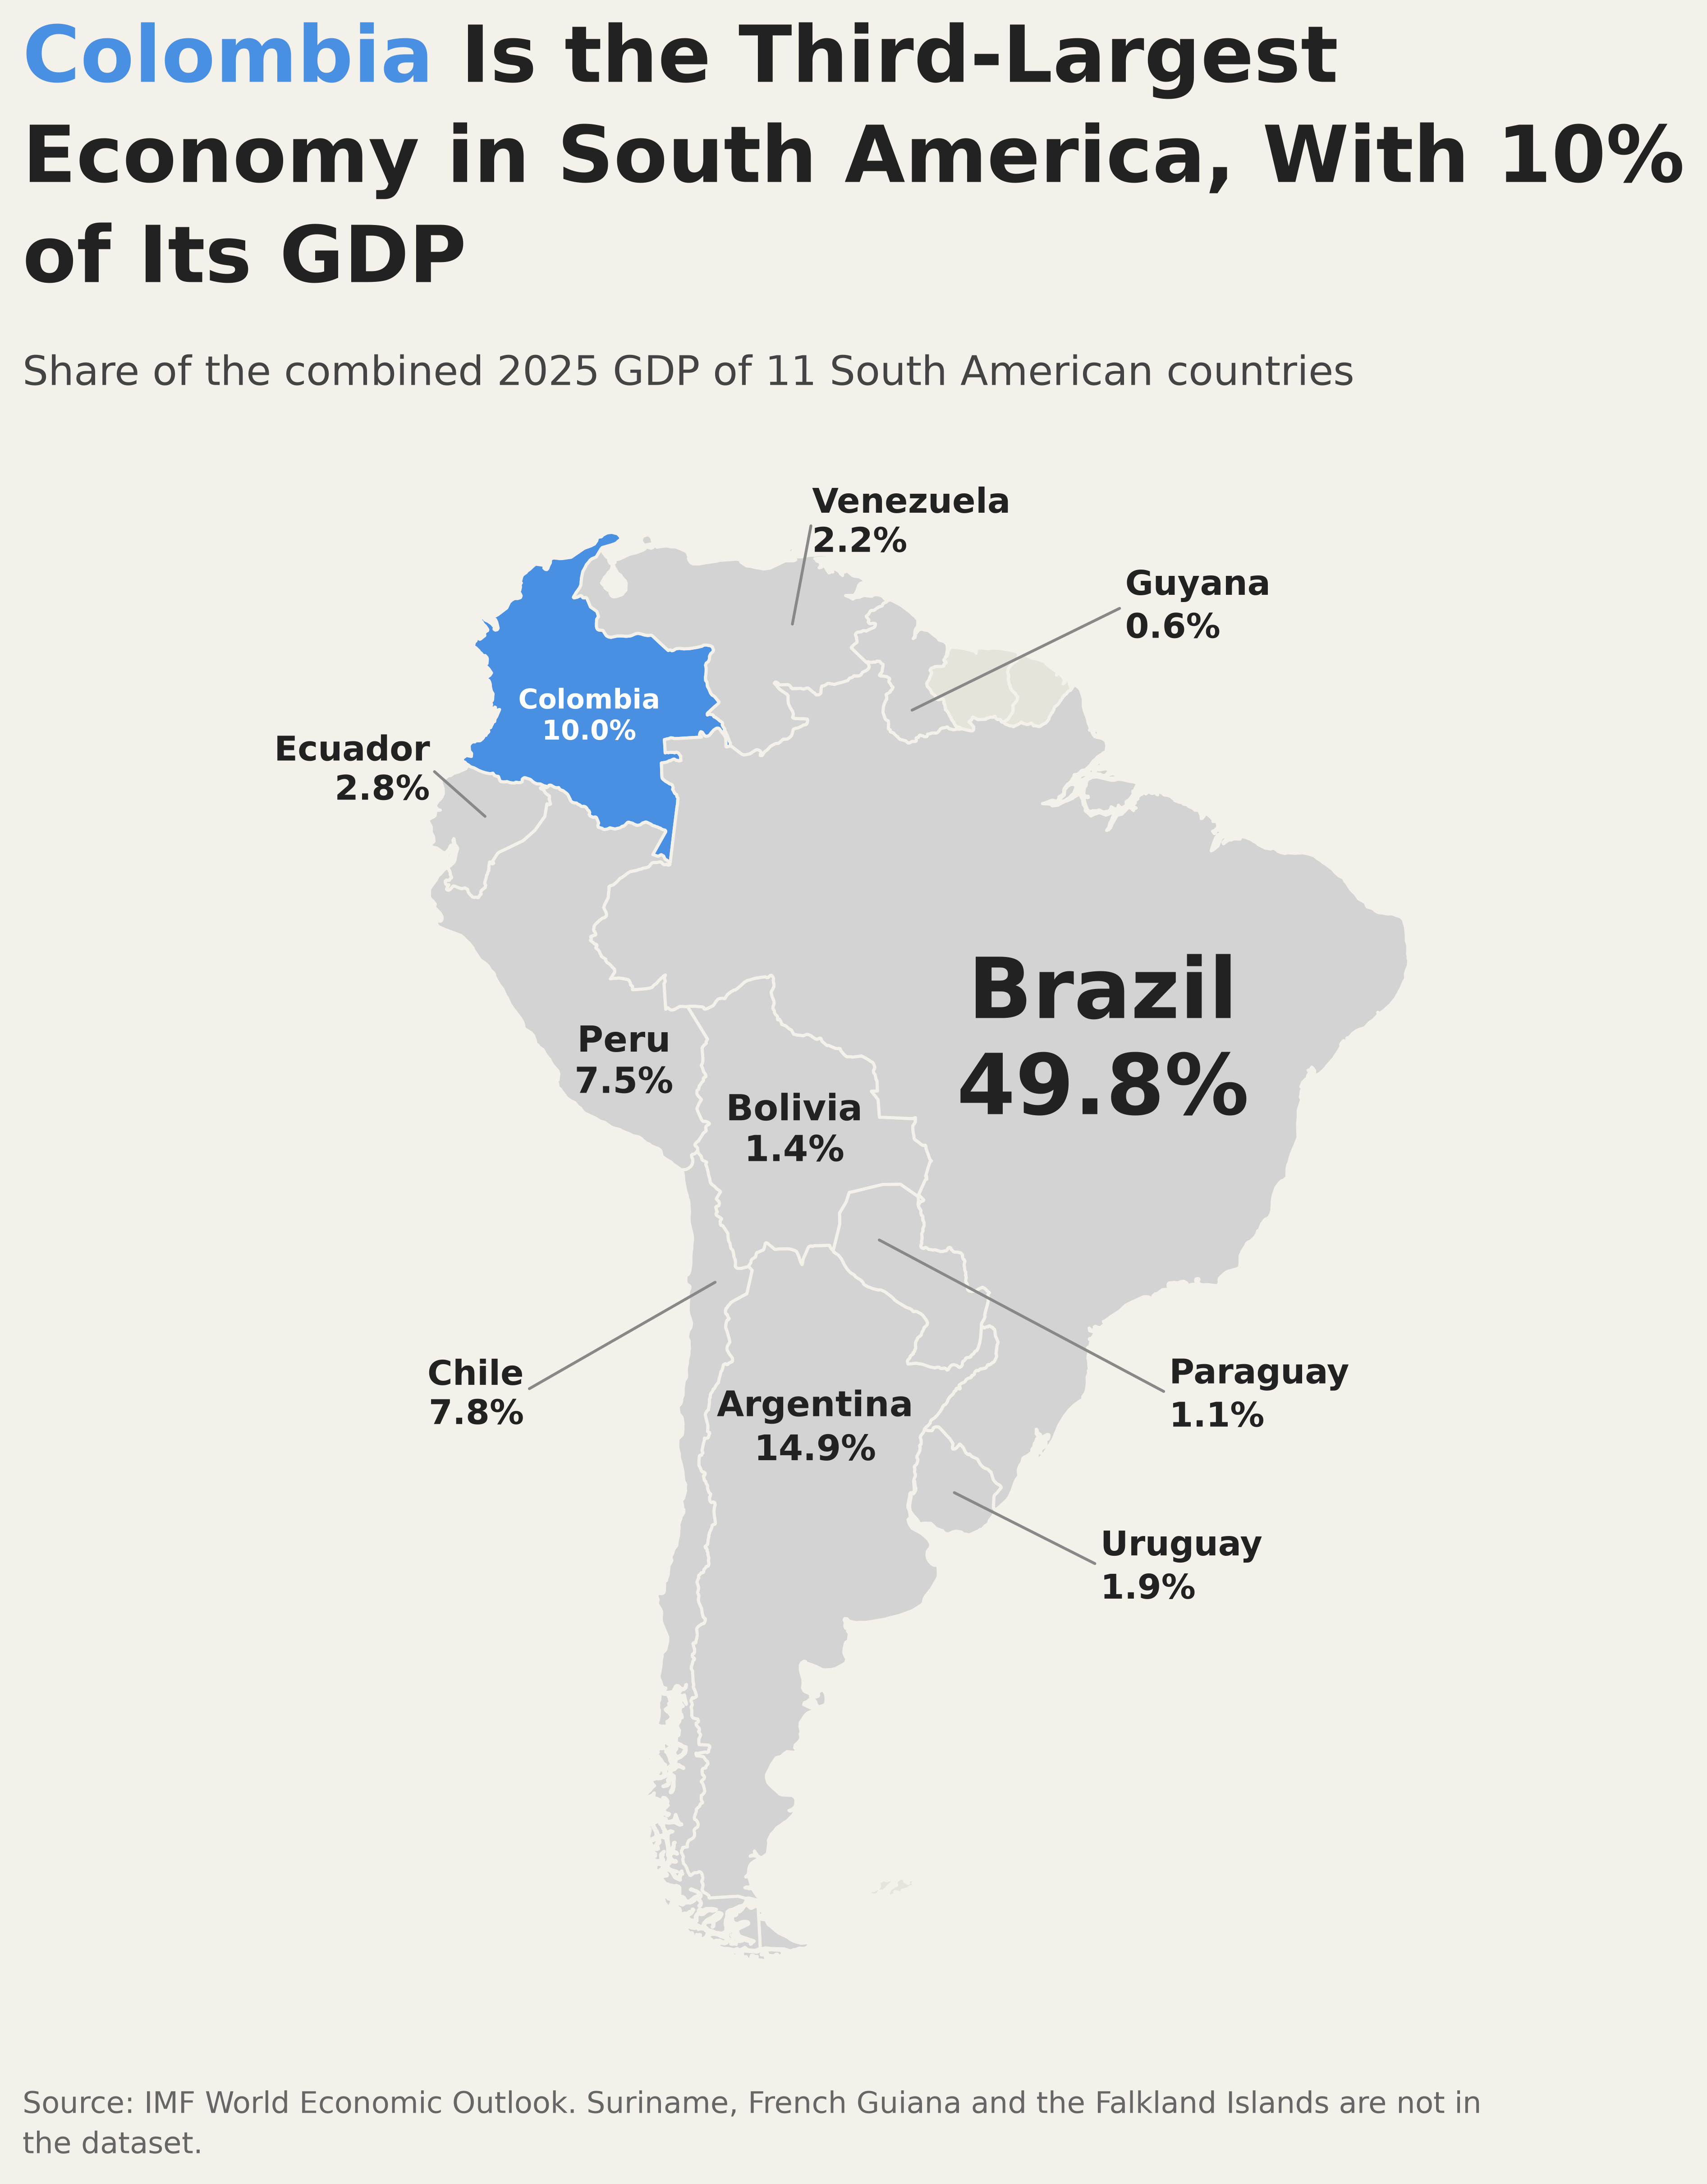

In [6]:
background = "#F4F1EA"
colombia = "#4a90e2"
gray = "#D3D3D3"
nodata = "#E6E3DB"
ink = "#222222"

assert share_2025.rank(ascending=False)["Colombia"] == 3
TITLE = (
    f"Colombia Is the Third-Largest Economy in South America, "
    f"With {share_2025['Colombia']:.0f}% of Its GDP"
)
SUBTITLE = "Share of the combined 2025 GDP of 11 South American countries"
FOOTNOTE = (
    "Source: IMF World Economic Outlook. "
    "Suriname, French Guiana and the Falkland Islands are not in the dataset."
)

# Labels sit at each country's pole of inaccessibility and shrink until they fit
# inside its border; those that never fit go to the ocean at "out" (lon, lat).
OUTSIDE = {
    "Chile": {"out": (-80, -27.5), "ha": "right"},
    "Ecuador": {"out": (-80.5, 1.5), "ha": "right"},
    "Uruguay": {"out": (-47, -36), "ha": "left"},
    "Guyana": {"out": (-49.5, 8.5), "ha": "left"},
    "Paraguay": {"out": (-44, -28), "ha": "left"},
    "Venezuela": {"out": (-63, 12.6), "ha": "left"},
}
MIN_SIZE = 8


def xy(lon, lat):
    """Project a lon/lat pair into the map CRS."""
    p = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326").to_crs(CRS).iloc[0]
    return p.x, p.y


def pole(geom):
    """Point deepest inside the largest part of a country (islands ignored)."""
    part = max(geom.geoms, key=lambda g: g.area) if hasattr(geom, "geoms") else geom
    return polylabel(part, tolerance=1000)


fig = plt.figure(figsize=(8.64, 10), dpi=500, facecolor=background)  # 1080 x 1350 px
ax = fig.add_axes([0.02, 0.07, 0.96, 0.70], facecolor=background)

fill = world["share"].notna().map({True: gray, False: nodata})
fill[world["ADMIN"] == "Colombia"] = colombia
world.plot(ax=ax, color=fill, edgecolor=background, linewidth=1.0)
ax.set_axis_off()
fig.canvas.draw()

geoms = world.set_index("ADMIN").geometry
renderer = fig.canvas.get_renderer()
to_data = ax.transData.inverted()


def fits(t, geom):
    """True if the text's bounding box lies fully inside the country."""
    bb = t.get_window_extent(renderer).transformed(to_data)
    return geom.contains(box(bb.x0, bb.y0, bb.x1, bb.y1))


for name, pct in share_2025.items():
    geom = geoms[name]
    pt = pole(geom)
    color = "white" if name == "Colombia" else ink
    text = f"{name}\n{pct:.1f}%"
    kw = dict(ha="center", va="center", fontweight="bold", linespacing=1.15)
    size = 11 + pct * 0.32
    t = ax.text(pt.x, pt.y, text, fontsize=size, color=color, **kw)
    while not fits(t, geom) and size > MIN_SIZE:
        size -= 0.5
        t.set_fontsize(size)
    if fits(t, geom):
        continue
    t.remove()
    cfg = OUTSIDE[name]
    tx, ty = xy(*cfg["out"])
    ax.annotate(
        "", xy=(pt.x, pt.y), xytext=(tx, ty),
        arrowprops=dict(arrowstyle="-", color="#888888", lw=0.9, shrinkA=2, shrinkB=0),
    )
    ax.text(tx, ty, text, fontsize=11, color=ink, **dict(kw, ha=cfg["ha"]))

title_lines = textwrap.wrap(TITLE, 34)
sub = "\n".join(textwrap.wrap(SUBTITLE, 62))

title_kw = dict(ha="left", va="baseline", fontsize=25, fontweight="bold")
x0, y0, pitch = 0.04, 0.938, 0.0444


def text_width(s):
    t = fig.text(0, 0, s, **title_kw)
    w = t.get_window_extent(renderer).width / fig.bbox.width
    t.remove()
    return w


for i, line in enumerate(title_lines):
    y = y0 - i * pitch
    if line.startswith("Colombia"):
        rest = line[len("Colombia"):].lstrip()
        fig.text(x0, y, "Colombia", color=colombia, **title_kw)
        fig.text(x0 + text_width(line) - text_width(rest), y, rest, color=ink, **title_kw)
    else:
        fig.text(x0, y, line, color=ink, **title_kw)
fig.text(0.04, 0.822, sub, ha="left", va="top", fontsize=13, color="#444444",
         linespacing=1.3)
fig.text(0.04, 0.05, "\n".join(textwrap.wrap(FOOTNOTE, 95)), ha="left", va="top",
         fontsize=9.5, color="#666666", linespacing=1.3)

plt.show()